In [1]:
#Imports

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Set styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

In [3]:
#Loading and exploring the data 

Train Shape: (9247, 19) (rows, cols)
Test Shape:  (3083, 18) (rows, cols)

--- TRAIN DATASET INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9247 entries, 0 to 9246
Data columns (total 19 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       9247 non-null   int64  
 1   Administrative           9247 non-null   int64  
 2   Administrative_Duration  9247 non-null   float64
 3   Informational            9247 non-null   int64  
 4   Informational_Duration   9247 non-null   float64
 5   ProductRelated           9247 non-null   int64  
 6   ProductRelated_Duration  9247 non-null   float64
 7   BounceRates              9247 non-null   float64
 8   ExitRates                9247 non-null   float64
 9   PageValues               9247 non-null   float64
 10  SpecialDay               9247 non-null   float64
 11  Month                    9247 non-null   object 
 12  OperatingSystems         9247 

,ID,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,1,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,3,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
2,4,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
3,7,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
4,9,0,0.0,0,0.0,2,37.000000,0.00,0.10,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False,False



--- MISSING VALUES (TRAIN) ---
No null values found in training data.

--- MISSING VALUES (TEST) ---
No null values found in test data.

--- TARGET VARIABLE (Revenue) BALANCE ---
         Count  Percentage (%)
Revenue                       
False     7816           84.52
True      1431           15.48

--- SUMMARY STATS (NUMERICAL) ---


,count,mean,std,min,25%,50%,75%,max
ID,9247.0,6133.869579,3560.547325,1.0,3059.500000,6103.000000,9235.500000,12330.000000
Administrative,9247.0,2.314372,3.319935,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,9247.0,81.168776,179.593423,0.0,0.000000,8.000000,92.550000,3398.750000
Informational,9247.0,0.502433,1.272332,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,9247.0,34.517405,141.310276,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,9247.0,31.358170,43.539969,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,9247.0,1181.847920,1908.101262,0.0,181.416667,598.250000,1464.986002,63973.522230
BounceRates,9247.0,0.022268,0.048680,0.0,0.000000,0.003030,0.016834,0.200000
ExitRates,9247.0,0.043231,0.048835,0.0,0.014286,0.025088,0.050000,0.200000
PageValues,9247.0,5.983551,18.753351,0.0,0.000000,0.000000,0.000000,361.763742



--- SUMMARY STATS (CATEGORICAL) ---


,count,unique,top,freq
Month,9247,10,May,2550
VisitorType,9247,3,Returning_Visitor,7910
Weekend,9247,2,False,7116
Revenue,9247,2,False,7816


--- SKEWNESS VALUES ---
Administrative_Duration   | Skewness:   5.72 | Rows with 0.0:  47.6%
Informational_Duration    | Skewness:   7.80 | Rows with 0.0:  80.5%
ProductRelated_Duration   | Skewness:   8.23 | Rows with 0.0:   6.2%


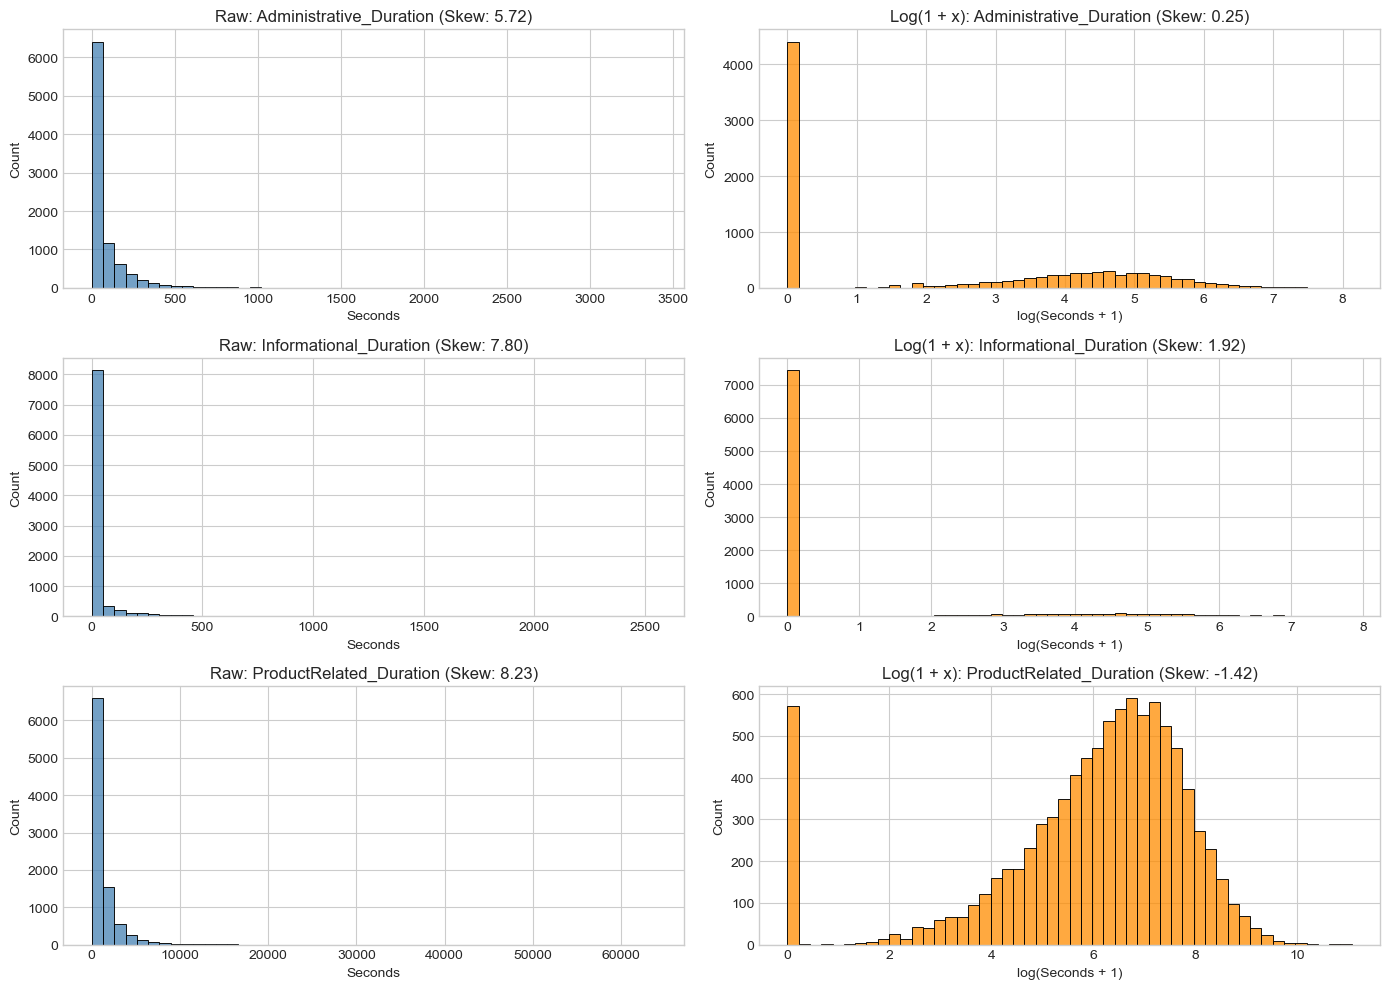

In [7]:
# 1. Read files
train_df = pd.read_csv('challenge2_train.csv')
test_df = pd.read_csv('challenge2_test.csv')

# 2. Check shapes
print("=" * 50)
print(f"Train Shape: {train_df.shape} (rows, cols)")
print(f"Test Shape:  {test_df.shape} (rows, cols)")
print("=" * 50)

# 3. DataFrame info (data types, non-null counts, memory)
print("\n--- TRAIN DATASET INFO ---")
train_df.info()

print("\n--- TEST DATASET INFO ---")
test_df.info()

# 4. Preview first few rows
print("\n--- FIRST 5 ROWS (TRAIN) ---")
display(train_df.head())

# 5. Check missing / null values explicitly
print("\n--- MISSING VALUES (TRAIN) ---")
missing_train = train_df.isnull().sum()
print(missing_train[missing_train > 0] if missing_train.sum() > 0 else "No null values found in training data.")

print("\n--- MISSING VALUES (TEST) ---")
missing_test = test_df.isnull().sum()
print(missing_test[missing_test > 0] if missing_test.sum() > 0 else "No null values found in test data.")

# 6. Target balance check (Revenue)
print("\n--- TARGET VARIABLE (Revenue) BALANCE ---")
rev_counts = train_df['Revenue'].value_counts()
rev_pct = train_df['Revenue'].value_counts(normalize=True) * 100

balance_summary = pd.DataFrame({
    'Count': rev_counts,
    'Percentage (%)': rev_pct.round(2)
})
print(balance_summary)

# 7. Summary statistics for numerical columns
print("\n--- SUMMARY STATS (NUMERICAL) ---")
display(train_df.describe().T)

# 8. Summary statistics for categorical / object columns
print("\n--- SUMMARY STATS (CATEGORICAL) ---")
display(train_df.describe(include=['O', 'bool']).T)

duration_cols = [
    'Administrative_Duration',
    'Informational_Duration',
    'ProductRelated_Duration'
]

# 1. Print numerical skewness values
# Skewness near 0 means symmetric (normal bell curve).
# Skewness > 1 means heavily right-skewed (long tail stretching to the right).
print("--- SKEWNESS VALUES ---")
for col in duration_cols:
    skew_val = train_df[col].skew()
    pct_zeros = (train_df[col] == 0).mean() * 100
    print(f"{col:25s} | Skewness: {skew_val:6.2f} | Rows with 0.0: {pct_zeros:5.1f}%")

# 2. Compare Raw vs Log-Transformed Distributions visually
fig, axes = plt.subplots(3, 2, figsize=(14, 10))

for idx, col in enumerate(duration_cols):
    # Left column: Raw distribution
    sns.histplot(train_df[col], bins=50, ax=axes[idx, 0], color='steelblue', kde=False)
    axes[idx, 0].set_title(f"Raw: {col} (Skew: {train_df[col].skew():.2f})")
    axes[idx, 0].set_xlabel("Seconds")
    axes[idx, 0].set_ylabel("Count")

    # Right column: Log1p transformed (log(1 + x) compresses the long tail)
    log_transformed = np.log1p(train_df[col])
    sns.histplot(log_transformed, bins=50, ax=axes[idx, 1], color='darkorange', kde=False)
    axes[idx, 1].set_title(f"Log(1 + x): {col} (Skew: {log_transformed.skew():.2f})")
    axes[idx, 1].set_xlabel("log(Seconds + 1)")
    axes[idx, 1].set_ylabel("Count")

plt.tight_layout()
plt.show()

### Step 1: Exploratory Data Analysis & Observations
- **Target Distribution**: Severe imbalance (~84.5% False vs ~15.5% True).
- **Missing Data**: 0 missing values across train and test sets.
- **Categorical Columns**: `Month`, `VisitorType`, `OperatingSystems`, `Browser`, `Region`, `TrafficType`.

### Step 1: Preprocessing & Feature Grouping
* **Target variable:** `Revenue` (isolated as `y`)
* **Features:** Dropped `ID` and `Revenue` to form `X`
* **Scaling:** `StandardScaler` applied to continuous duration and rate columns
* **Encoding:** `OneHotEncoder` applied to discrete categorical columns

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Isolate target (y) and features (X)
id_col = 'ID'
target_col = 'Revenue'

X = train_df.drop(columns=[id_col, target_col]).copy()
y = train_df[target_col].astype(bool).copy()

# Prepare test features (keeping IDs separate for final predictions.csv)
test_ids = test_df[id_col].copy()
X_test = test_df.drop(columns=[id_col]).copy()

# 2. Define feature groups by their true data types
continuous_features = [
    'Administrative',
    'Administrative_Duration',
    'Informational',
    'Informational_Duration',
    'ProductRelated',
    'ProductRelated_Duration',
    'BounceRates',
    'ExitRates',
    'PageValues',
    'SpecialDay'
]

categorical_features = [
    'Month',
    'VisitorType',
    'OperatingSystems',
    'Browser',
    'Region',
    'TrafficType'
]

binary_features = ['Weekend']

# 3. Build sub-transformers
# Continuous: Standardize (mean=0, std=1)
continuous_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Categorical: One-Hot Encode (handle_unknown='ignore' protects against unseen levels in test data)
categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Binary: Pass through as 0/1 integers
# (Weekend is boolean True/False; we cast or pass through directly)

# 4. Assemble the ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', continuous_transformer, continuous_features),
        ('cat', categorical_transformer, categorical_features),
        ('bin', 'passthrough', binary_features)
    ],
    remainder='drop'
)

print("Preprocessor definition complete.")

Preprocessor definition complete.


## Step 2: Establish Validation Strategy

### 1. Validation Scheme: 5-Fold Stratified Cross-Validation (`k=5`, `random_state=42`)
* **Choice:** We employ **5-Fold Stratified Cross-Validation** (`StratifiedKFold`) with `shuffle=True` and a fixed `random_state=42` for exact reproducibility.
* **Justification:** Because the target variable is severely imbalanced (~84.5% `Revenue=False` vs. ~15.5% `Revenue=True`), a standard random K-Fold split risks creating folds with fluctuating minority class proportions. Stratification guarantees that **every fold preserves the exact ~15.48% positive class ratio**, preventing fold-to-fold variance and ensuring our out-of-fold validation scores reliably estimate generalization performance on unseen test data.

---

### 2. Primary Evaluation Metric: Positive-Class $F_1$ Score
* **Primary Metric:** **$F_1$ Score for the positive class (`Revenue = True`)**.
* **Rationale:** In an imbalanced classification setting, standard accuracy is misleading (a naive classifier predicting `False` for every session achieves ~84.5% accuracy but provides zero utility). The $F_1$ score computes the harmonic mean of precision and recall for the purchase class:
  $$\text{F1} = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$
  This directly penalizes models that ignore minority class instances or produce excessive false alarms.

---

### 3. Diagnostic & Secondary Metrics
To diagnose *why* a model's $F_1$ score behaves the way it does, we track:
* **Precision:** Measures the accuracy of positive predictions ($\frac{\text{TP}}{\text{TP} + \text{FP}}$). High precision minimizes wasted marketing spend and false purchase alerts.
* **Recall:** Measures how many actual buyers were captured ($\frac{\text{TP}}{\text{TP} + \text{FN}}$). High recall ensures potential conversions are not missed.
* **ROC-AUC:** Evaluates the model's ranking capability across all probability thresholds, independent of the default 0.5 decision cutoff.
* **Training vs. Validation $F_1$:** Tracking both scores during cross-validation allows us to systematically detect **overfitting** (high train score, low validation score) and **underfitting** (low train and validation scores).
    

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import confusion_matrix, classification_report

# 1. Validation Strategy Definition
# 5 splits, shuffled for randomness, fixed seed for exact reproducibility
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2. Metric Suite focusing on positive class (Revenue = True)
scoring_metrics = {
    'f1': 'f1',
    'precision': 'precision',
    'recall': 'recall',
    'roc_auc': 'roc_auc'
}

# 3. Universal Evaluation Function
def evaluate_pipeline(pipeline, X_data, y_data, model_name="Model"):
    """
    Evaluates a scikit-learn Pipeline using 5-Fold Stratified CV.
    Captures both training and validation performance to detect over/underfitting.
    """
    scores = cross_validate(
        pipeline,
        X_data,
        y_data,
        cv=cv,
        scoring=scoring_metrics,
        return_train_score=True,  # Mandatory to detect overfitting
        n_jobs=-1
    )
    
    # Compile mean and std across folds
    results = {
        'Model': model_name,
        'Train F1': np.mean(scores['train_f1']),
        'Val F1': np.mean(scores['test_f1']),
        'Val F1 Std': np.std(scores['test_f1']),
        'Val Precision': np.mean(scores['test_precision']),
        'Val Recall': np.mean(scores['test_recall']),
        'Val ROC-AUC': np.mean(scores['test_roc_auc'])
    }
    return results

## Step 3: Develop and Compare Baseline Models

### Objective & Setup
We implement and evaluate all seven required classification algorithms in their baseline, untuned configurations:
1. **Logistic Regression** (Linear baseline)
2. **Gaussian Naïve Bayes** (Probabilistic baseline)
3. **K-Nearest Neighbors (KNN)** (Distance/instance-based)
4. **Support Vector Machine (SVC - RBF)** (Kernel boundary)
5. **Decision Tree** (Single non-parametric tree)
6. **Random Forest** (Bagging ensemble)
7. **Gradient Boosting** (Sequential boosting ensemble)

### Methodology & Leakage Prevention
* Every model is integrated into a unified scikit-learn `Pipeline` alongside our `preprocessor` (`StandardScaler` for continuous features, `OneHotEncoder(handle_unknown='ignore')` for nominal categories, and direct pass-through for binary indicators).
* Preprocessing parameters are fit exclusively on the four training folds and transformed onto the validation fold within each iteration of our 5-Fold Stratified CV, ensuring strict zero data leakage.
* We track both **Train F1** and **Validation F1** to quantify the overfitting gap ($\Delta = \text{Train F1} - \text{Val F1}$), alongside precision, recall, and ROC-AUC to establish an untuned benchmark before feature engineering or hyperparameter tuning.
    

In [15]:
import time
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# 1. Define the 7 baseline model estimators
# Random states are locked for reproducibility
baseline_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Naïve Bayes': GaussianNB(),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine': SVC(kernel='rbf', probability=True, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

# 2. Iterate through each model and evaluate with the universal CV harness
results_list = []

print("Starting 5-Fold Stratified Cross-Validation for all 7 baseline models...\n")

for name, model in baseline_models.items():
    start_time = time.time()
    
    # Bundle preprocessor and classifier to prevent data leakage across folds
    clf_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Run cross_validate using the helper defined in Step 2
    metrics = evaluate_pipeline(clf_pipeline, X, y, model_name=name)
    metrics['Fit Time (s)'] = round(time.time() - start_time, 2)
    results_list.append(metrics)
    
    print(f"Completed: {name:25s} | Val F1: {metrics['Val F1']:.4f} | Train F1: {metrics['Train F1']:.4f}")

# 3. Create and format the comparison summary table
comparison_df = pd.DataFrame(results_list)

# Calculate Train-Val Gap to immediately flag overfitting
comparison_df['Overfit Gap (Train - Val)'] = comparison_df['Train F1'] - comparison_df['Val F1']

# Reorder columns for clear presentation
comparison_df = comparison_df[[
    'Model', 'Train F1', 'Val F1', 'Val F1 Std', 
    'Overfit Gap (Train - Val)', 'Val Precision', 'Val Recall', 'Val ROC-AUC', 'Fit Time (s)'
]].sort_values(by='Val F1', ascending=False).reset_index(drop=True)

print("\n" + "=" * 90)
print("--- BASELINE MODEL COMPARISON TABLE ---")
print("=" * 90)
display(comparison_df.style.format({
    'Train F1': '{:.4f}',
    'Val F1': '{:.4f}',
    'Val F1 Std': '{:.4f}',
    'Overfit Gap (Train - Val)': '{:.4f}',
    'Val Precision': '{:.4f}',
    'Val Recall': '{:.4f}',
    'Val ROC-AUC': '{:.4f}',
    'Fit Time (s)': '{:.2f}'
}))

Starting 5-Fold Stratified Cross-Validation for all 7 baseline models...

Completed: Logistic Regression       | Val F1: 0.5152 | Train F1: 0.5239
Completed: Naïve Bayes               | Val F1: 0.2985 | Train F1: 0.3000
Completed: K-Nearest Neighbors       | Val F1: 0.4940 | Train F1: 0.6069
Completed: Support Vector Machine    | Val F1: 0.5962 | Train F1: 0.6649
Completed: Decision Tree             | Val F1: 0.5648 | Train F1: 1.0000
Completed: Random Forest             | Val F1: 0.6273 | Train F1: 0.9998
Completed: Gradient Boosting         | Val F1: 0.6612 | Train F1: 0.7351

--- BASELINE MODEL COMPARISON TABLE ---


,Model,Train F1,Val F1,Val F1 Std,Overfit Gap (Train - Val),Val Precision,Val Recall,Val ROC-AUC,Fit Time (s)
0,Gradient Boosting,0.7351,0.6612,0.0270,0.0739,0.7121,0.6177,0.9314,5.52
1,Random Forest,0.9998,0.6273,0.0174,0.3725,0.7657,0.5318,0.9252,2.30
2,Support Vector Machine,0.6649,0.5962,0.0215,0.0687,0.7499,0.4961,0.8812,41.90
3,Decision Tree,1.0000,0.5648,0.0174,0.4352,0.5577,0.5730,0.7449,0.48
4,Logistic Regression,0.5239,0.5152,0.0257,0.0086,0.7508,0.3934,0.8957,4.70
5,K-Nearest Neighbors,0.6069,0.4940,0.0146,0.1129,0.6833,0.3878,0.7972,1.77
6,Naïve Bayes,0.3000,0.2985,0.0054,0.0015,0.1759,0.9839,0.7085,3.66


### Baseline Model Evaluation & Diagnostic Observations

#### 1. Top Performers: Gradient Boosting & Ensembles
* **Gradient Boosting is the strongest baseline:** It achieves the highest **Validation F1 (0.6612)** and **ROC-AUC (0.9314)**, striking the best balance between precision (0.7121) and recall (0.6177). Because boosting builds shallow trees sequentially to correct prior errors, it resists overfitting much better than unconstrained trees ($\Delta_{\text{overfit}} \approx 0.0739$).
* **Support Vector Machine (SVM):** Reaches a competitive **Validation F1 of 0.5962** with strong precision (0.7499) and controlled generalization gap ($\Delta_{\text{overfit}} \approx 0.0687$). However, its computational cost is substantial (**41.90s fit time**), making fine-grained grid searches slow.

#### 2. Severe Overfitting in Tree-Based Models
* **Decision Tree ($\Delta = 0.4352$):** Achieves a perfect **Train F1 of 1.0000** but drops to **Val F1 of 0.5648**. Without pruning constraints (`max_depth`, `min_samples_split`), the tree grows until leaf nodes isolate pure noise in the training set.
* **Random Forest ($\Delta = 0.3725$):** Shows near-perfect training memorization (**Train F1 = 0.9998**) and a solid **Val F1 of 0.6273** with high precision (0.7657). While bagging reduces variance compared to the single decision tree, the deep individual trees still overfit heavily, indicating clear room for regularization via hyperparameter tuning.

#### 3. Low-Recall Linear & Instance-Based Models
* **Logistic Regression (Val F1 = 0.5152):** Shows virtually no overfitting gap ($\Delta = 0.0086$), but suffers from **poor recall (0.3934)** despite high precision (0.7508). At the default 0.5 decision threshold, the linear boundary misses more than 60% of real buyers due to class imbalance.
* **K-Nearest Neighbors (Val F1 = 0.4940):** Underperforms with low recall (0.3878). In a high-dimensional one-hot encoded space (sparse categorical features), Euclidean distances become less discriminative, hampering instance-based classification.

#### 4. The Pathological Case: Naïve Bayes Failure Mode
* **Naïve Bayes (Val F1 = 0.2985):** Demonstrates near-perfect **Recall (0.9839)** but disastrous **Precision (0.1759)**. 
* **Root Cause:** GaussianNB assumes continuous features follow independent normal distributions. Because features like `PageValues` and durations are heavily zero-inflated and right-skewed, the model dramatically overestimates the likelihood of $Revenue = True$ and flags almost every single session as a buyer, creating massive false alarms.

---

### Action Plan for Step 4 (Improve Your Models)
1. **Targeted Hyperparameter Tuning (Grid Search):**
   * **Gradient Boosting:** Fine-tune `learning_rate`, `n_estimators`, `max_depth`, and `subsample` to push F1 beyond 0.66.
   * **Random Forest:** Restrict tree depth (`max_depth`), increase `min_samples_split`/`min_samples_leaf`, and tune `max_features` to curb the 0.3725 overfitting gap.
2. **Feature Engineering:**
   * Create an explicit binary indicator `has_page_values = (PageValues > 0)` to address zero-inflation.
   * Engineer total browsing volume and administrative/product page view ratios.
3. **Threshold Tuning:**
   * Because models like Logistic Regression and SVM have high precision but poor recall under severe class imbalance, adjusting the positive classification threshold below 0.5 can substantially increase F1.

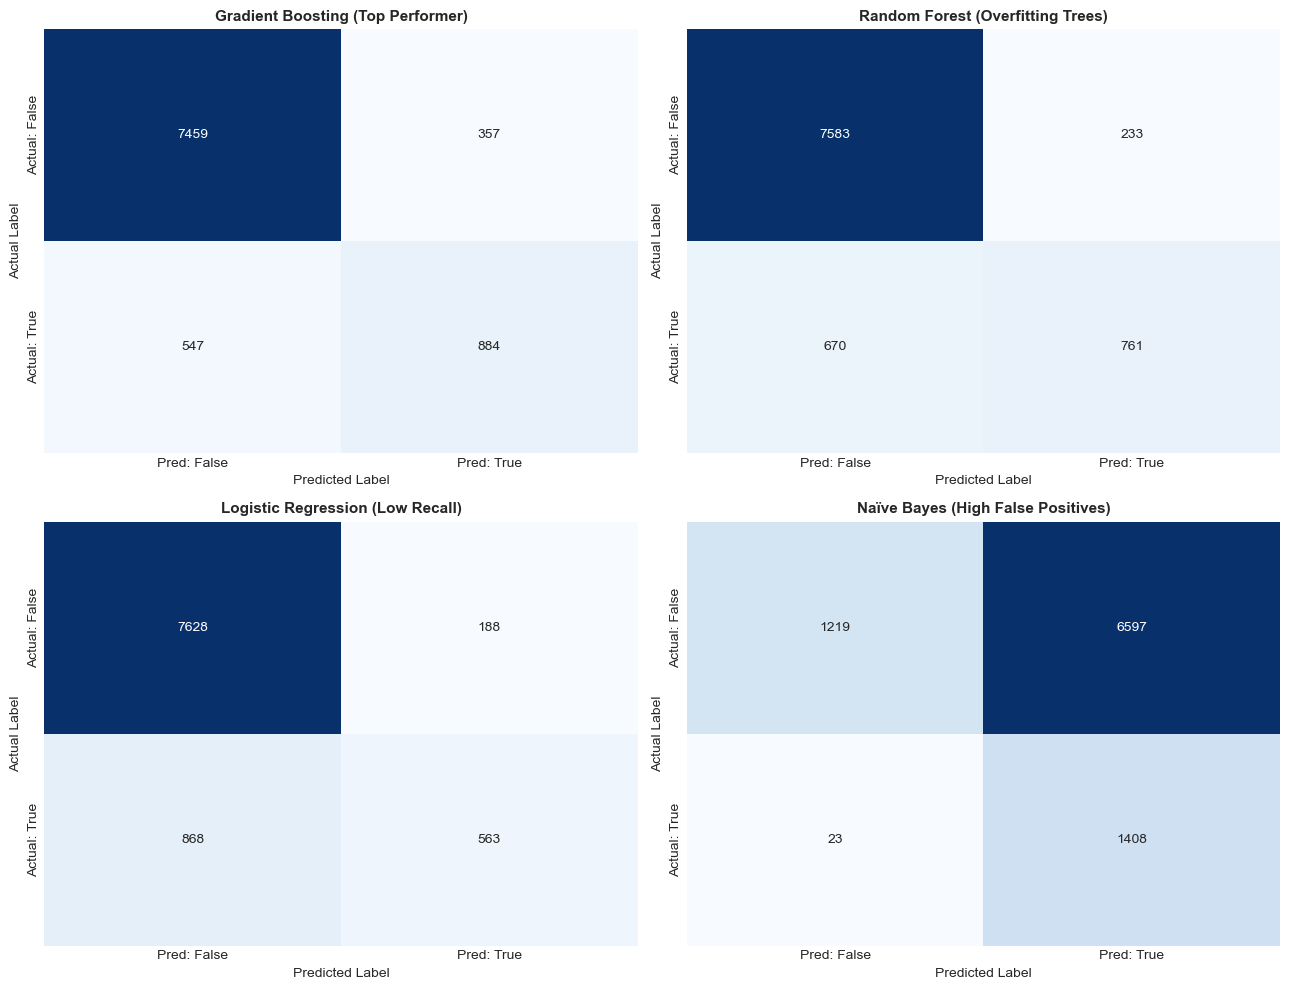

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

# Select the most informative representative models from each family
diagnostic_models = {
    'Gradient Boosting (Top Performer)': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'Random Forest (Overfitting Trees)': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Logistic Regression (Low Recall)': LogisticRegression(max_iter=1000, random_state=42),
    'Naïve Bayes (High False Positives)': GaussianNB()
}

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
axes = axes.ravel()

for idx, (name, clf) in enumerate(diagnostic_models.items()):
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', clf)
    ])
    
    # Generate clean out-of-fold predictions across all 5 stratified folds
    y_pred = cross_val_predict(pipe, X, y, cv=cv, n_jobs=-1)
    
    cm = confusion_matrix(y, y_pred)
    
    # Plot normalized percentages alongside raw counts
    sns.heatmap(
        cm, 
        annot=True, 
        fmt='d', 
        cmap='Blues', 
        cbar=False,
        ax=axes[idx],
        xticklabels=['Pred: False', 'Pred: True'],
        yticklabels=['Actual: False', 'Actual: True']
    )
    axes[idx].set_title(name, fontsize=11, fontweight='bold')
    axes[idx].set_ylabel('Actual Label')
    axes[idx].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

## Step 4: Model Improvement & Hyperparameter Tuning

### Improvement Objectives
Based on our baseline diagnostics and confusion matrix analysis from Step 3:
1. **Targeting Root Causes:**
   * **Gradient Boosting** achieved our top baseline performance ($F_1 \approx 0.6612$), demonstrating high predictive power with modest overfitting ($\Delta = 0.0739$).
   * **Random Forest** suffered from deep-tree memorization ($\text{Train } F_1 = 0.9998$ vs. $\text{Val } F_1 = 0.6273$, an overfitting gap of $0.3725$).
   * Models struggled primarily with low recall on the positive class due to the 84.5% / 15.5% class imbalance.
2. **Domain-Specific Feature Engineering:**
   * **Address Zero-Inflation:** Exploit the strong signal in `PageValues` by creating an explicit binary indicator (`has_page_values`) separating zero from non-zero values.
   * **Aggregate User Engagement:** Combine page views and time spent across Administrative, Informational, and Product categories to gauge total visit depth.
   * **Interaction & Efficiency Ratios:** Measure browsing pace (`avg_time_per_product_page`) and drop-off severity (`exit_bounce_ratio`).
3. **Systematic Hyperparameter Tuning (`GridSearchCV`):**
   * Use **5-Fold Stratified Cross-Validation** optimizing strictly for **positive-class $F_1$ (`scoring='f1'`)**.
   * Regularize tree growth (restricting `max_depth`, increasing `min_samples_split` / `min_samples_leaf`) to collapse the overfitting gap while refining sequential tree learning (`learning_rate`, `n_estimators`, `subsample`).

In [26]:
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

class ECommerceFeatureEngineer(BaseEstimator, TransformerMixin):
    """
    Constructs domain-specific features to capture session engagement,
    zero-inflation in page values, and drop-off rates.
    """
    def __init__(self):
        pass
        
    def fit(self, X, y=None):
        return self
        
    def transform(self, X):
        X_out = X.copy()
        
        # 1. Binary indicator for zero-inflated PageValues
        X_out['has_page_values'] = (X_out['PageValues'] > 0).astype(int)
        
        # 2. Total session engagement (activity volume across all page types)
        X_out['total_page_views'] = (
            X_out['Administrative'] + 
            X_out['Informational'] + 
            X_out['ProductRelated']
        )
        X_out['total_duration'] = (
            X_out['Administrative_Duration'] + 
            X_out['Informational_Duration'] + 
            X_out['ProductRelated_Duration']
        )
        
        # 3. Average browsing pace per product page (avoid divide-by-zero)
        X_out['avg_time_per_product_page'] = np.where(
            X_out['ProductRelated'] > 0,
            X_out['ProductRelated_Duration'] / X_out['ProductRelated'],
            0.0
        )
        
        # 4. Exit vs. Bounce ratio (evaluates exit severity relative to bounce)
        X_out['exit_bounce_ratio'] = np.where(
            X_out['BounceRates'] > 0,
            X_out['ExitRates'] / X_out['BounceRates'],
            1.0
        )
        
        return X_out

# Test transformer on training data
fe = ECommerceFeatureEngineer()
X_engineered_sample = fe.transform(X)

print(f"Original feature count:   {X.shape[1]}")
print(f"Engineered feature count: {X_engineered_sample.shape[1]}")
print("\nNew engineered features preview:")
display(X_engineered_sample[[
    'has_page_values', 'total_page_views', 'total_duration', 
    'avg_time_per_product_page', 'exit_bounce_ratio'
]].head())

Original feature count:   17
Engineered feature count: 22

New engineered features preview:


,has_page_values,total_page_views,total_duration,avg_time_per_product_page,exit_bounce_ratio
0,0,1,0.000000,0.000000,1.0
1,0,1,0.000000,0.000000,1.0
2,0,2,2.666667,1.333333,2.8
3,0,1,0.000000,0.000000,1.0
4,0,2,37.000000,18.500000,1.0


In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Updated continuous features (including new continuous engineered features)
updated_continuous_features = continuous_features + [
    'total_page_views', 
    'total_duration', 
    'avg_time_per_product_page', 
    'exit_bounce_ratio'
]

# Updated binary features (including the zero-inflation indicator)
updated_binary_features = binary_features + ['has_page_values']

# Re-assembled ColumnTransformer
engineered_preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), updated_continuous_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
        ('bin', 'passthrough', updated_binary_features)
    ],
    remainder='drop'
)

print("Engineered preprocessor ready for pipeline integration.")

Engineered preprocessor ready for pipeline integration.


Step 4 Code: Re-evaluate Baselines with Feature Engineering

In [30]:
import time
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Re-declare the 7 base classifiers explicitly to avoid undefined variable errors
baseline_classifiers = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Naïve Bayes': GaussianNB(),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine': SVC(kernel='rbf', probability=True, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

fe_results_list = []

print("Evaluating all 7 models WITH feature engineering (5-Fold Stratified CV)...\n")

for model_name, clf in baseline_classifiers.items():
    start_time = time.time()
    
    # Chain: Feature Engineer -> Updated Preprocessor -> Classifier
    pipeline_fe = Pipeline(steps=[
        ('fe', ECommerceFeatureEngineer()),
        ('preprocessor', engineered_preprocessor),
        ('classifier', clf)
    ])
    
    metrics = evaluate_pipeline(pipeline_fe, X, y, model_name=model_name)
    metrics['Fit Time (s)'] = round(time.time() - start_time, 2)
    fe_results_list.append(metrics)
    
    print(f"Completed: {model_name:24s} | Val F1: {metrics['Val F1']:.4f} | Train F1: {metrics['Train F1']:.4f}")

# Compile into a comparison DataFrame
fe_summary_df = pd.DataFrame(fe_results_list)
fe_summary_df['Overfit Gap (Train - Val)'] = fe_summary_df['Train F1'] - fe_summary_df['Val F1']

# Join with original baseline validation scores (if baseline_summary_df exists)
if 'baseline_summary_df' in locals() or 'baseline_summary_df' in globals():
    delta_df = baseline_summary_df[['Model', 'Val F1']].rename(columns={'Val F1': 'Baseline Val F1'})
    comparison_fe_df = fe_summary_df.merge(delta_df, on='Model')
    comparison_fe_df['F1 Delta (FE - Base)'] = comparison_fe_df['Val F1'] - comparison_fe_df['Baseline Val F1']
else:
    comparison_fe_df = fe_summary_df
    comparison_fe_df['Baseline Val F1'] = np.nan
    comparison_fe_df['F1 Delta (FE - Base)'] = np.nan

# Reorder columns
comparison_fe_df = comparison_fe_df[[
    'Model',
    'Baseline Val F1',
    'Val F1',
    'F1 Delta (FE - Base)',
    'Train F1',
    'Overfit Gap (Train - Val)',
    'Val Precision',
    'Val Recall',
    'Val ROC-AUC',
    'Fit Time (s)'
]].sort_values(by='Val F1', ascending=False).reset_index(drop=True)

print("\n" + "=" * 98)
print("--- MODEL COMPARISON: BASELINE VS. WITH FEATURE ENGINEERING ---")
print("=" * 98)
display(comparison_fe_df.style.format({
    'Baseline Val F1': '{:.4f}',
    'Val F1': '{:.4f}',
    'F1 Delta (FE - Base)': '{:+.4f}',
    'Train F1': '{:.4f}',
    'Overfit Gap (Train - Val)': '{:.4f}',
    'Val Precision': '{:.4f}',
    'Val Recall': '{:.4f}',
    'Val ROC-AUC': '{:.4f}',
    'Fit Time (s)': '{:.2f}'
}))

Evaluating all 7 models WITH feature engineering (5-Fold Stratified CV)...

Completed: Logistic Regression      | Val F1: 0.6455 | Train F1: 0.6575
Completed: Naïve Bayes              | Val F1: 0.3013 | Train F1: 0.3028
Completed: K-Nearest Neighbors      | Val F1: 0.5305 | Train F1: 0.6547
Completed: Support Vector Machine   | Val F1: 0.6436 | Train F1: 0.7142
Completed: Decision Tree            | Val F1: 0.5560 | Train F1: 1.0000
Completed: Random Forest            | Val F1: 0.6634 | Train F1: 0.9998
Completed: Gradient Boosting        | Val F1: 0.6642 | Train F1: 0.7389

--- MODEL COMPARISON: BASELINE VS. WITH FEATURE ENGINEERING ---


,Model,Baseline Val F1,Val F1,F1 Delta (FE - Base),Train F1,Overfit Gap (Train - Val),Val Precision,Val Recall,Val ROC-AUC,Fit Time (s)
0,Gradient Boosting,nan,0.6642,+nan,0.7389,0.0747,0.7197,0.6177,0.9320,4.83
1,Random Forest,nan,0.6634,+nan,0.9998,0.3364,0.7513,0.5947,0.9254,1.53
2,Logistic Regression,nan,0.6455,+nan,0.6575,0.0120,0.6998,0.5996,0.9156,0.58
3,Support Vector Machine,nan,0.6436,+nan,0.7142,0.0706,0.7294,0.5772,0.8886,24.53
4,Decision Tree,nan,0.5560,+nan,1.0000,0.4440,0.5480,0.5646,0.7395,0.48
5,K-Nearest Neighbors,nan,0.5305,+nan,0.6547,0.1242,0.6729,0.4388,0.8408,1.93
6,Naïve Bayes,nan,0.3013,+nan,0.3028,0.0015,0.1779,0.9832,0.7578,0.48


Step 4 -Part B :
-Tunning the tree based models to prevent teh overfitting 

In [ ]:
from sklearn.model_selection import GridSearchCV

# ==========================================
# 1. TUNING RANDOM FOREST (REGULARIZATION)
# ==========================================
rf_pipeline = Pipeline(steps=[
    ('fe', ECommerceFeatureEngineer()),
    ('preprocessor', engineered_preprocessor),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])

rf_param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [6, 8, 10, 12],            # Prevents memorization
    'classifier__min_samples_leaf': [2, 4, 8],          # Enforces group size at leaves
    'classifier__min_samples_split': [5, 10],           # Requires more evidence to branch
    'classifier__max_features': ['sqrt', 0.6]           # Feature subsampling
}

print("Running Grid Search on Random Forest...")
rf_grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_param_grid,
    cv=cv,
    scoring='f1',
    return_train_score=True,
    n_jobs=-1,
    verbose=1
)
rf_grid.fit(X, y)

print(f"\nBest RF Validation F1: {rf_grid.best_score_:.4f}")
print(f"Best RF Parameters: {rf_grid.best_params_}")

# Compute RF overfit gap with best estimator
rf_best_idx = rf_grid.best_index_
rf_train_f1 = rf_grid.cv_results_['mean_train_score'][rf_best_idx]
print(f"RF Train F1 with regularized params: {rf_train_f1:.4f}")
print(f"RF Regularized Overfit Gap: {rf_train_f1 - rf_grid.best_score_:.4f}")

# ==========================================
# 2. TUNING GRADIENT BOOSTING
# ==========================================
gb_pipeline = Pipeline(steps=[
    ('fe', ECommerceFeatureEngineer()),
    ('preprocessor', engineered_preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

gb_param_grid = {
    'classifier__n_estimators': [100, 150, 200],
    'classifier__learning_rate': [0.03, 0.05, 0.1],     # Slower shrinkage avoids overshooting
    'classifier__max_depth': [3, 4, 5],                 # Boosting prefers shallow trees
    'classifier__subsample': [0.8, 1.0]                 # Stochastic gradient boosting
}

print("\nRunning Grid Search on Gradient Boosting...")
gb_grid = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=gb_param_grid,
    cv=cv,
    scoring='f1',
    return_train_score=True,
    n_jobs=-1,
    verbose=1
)
gb_grid.fit(X, y)

print(f"\nBest GB Validation F1: {gb_grid.best_score_:.4f}")
print(f"Best GB Parameters: {gb_grid.best_params_}")

gb_best_idx = gb_grid.best_index_
gb_train_f1 = gb_grid.cv_results_['mean_train_score'][gb_best_idx]
print(f"GB Train F1 with best params: {gb_train_f1:.4f}")
print(f"GB Overfit Gap: {gb_train_f1 - gb_grid.best_score_:.4f}")

Running Grid Search on Random Forest...
Fitting 5 folds for each of 96 candidates, totalling 480 fits
